# Тема: Моделирование связи частотного и классического определения вероятности
## Задача "Шляпа старосты"
Староста группы придумала систему для оправдания опоздавших студентов. В его «шляпе» лежат 8 свернутых бумажек с уникальными причинами. Из них 3 причины — «уважительные» (например, «сломался автобус», «застрял в лифте», «задержали в деканате»), а 5 причин — «нелепые» (например, «проспал», «кот не отпускал», «переосмысливал жизнь»). Сегодня на первую пару опоздали 3 студента. Староста наудачу вытягивает из шляпы ровно 3 бумажки без возвращения. Требуется найти вероятность того, что для студентов будут вытянуты ровно 2 уважительные причины и 1 нелепая.

### Теоретический расчет

Рассмотрим событие $A$ — извлечены 2 уважительные и 1 нелепая причина.

По классическому определению вероятность равна отношению числа благоприятствующих исходов $m$ к общему числу возможных исходов $n$:

$$P(A) = \frac{m}{n}$$

* $n$: общее число случаев выбора 3 бумажек из 8 (без учета порядка) определяется числом сочетаний $C_8^3$

$$n = C_8^3 = \frac{8!}{3!\cdot5!} = 56$$

* $m$: число благоприятствующих случаев вычисляется по правилу произведения. Выбор всех элементов может быть осуществлен путем умножения числа способов выбора 2 уважительных причин из 3 ($C_3^2$) на число способов выбора 1 нелепой из 5 ($C_5^1$)

$$m = C_3^2 \cdot C_5^1 = 3 \cdot 5 = 15$$

Искомая вероятность:

$$P(A) = \frac{15}{56} \approx 0.2679$$

Классическая вероятность: 0.2679
Частотная вероятность (N=5000): 0.2614


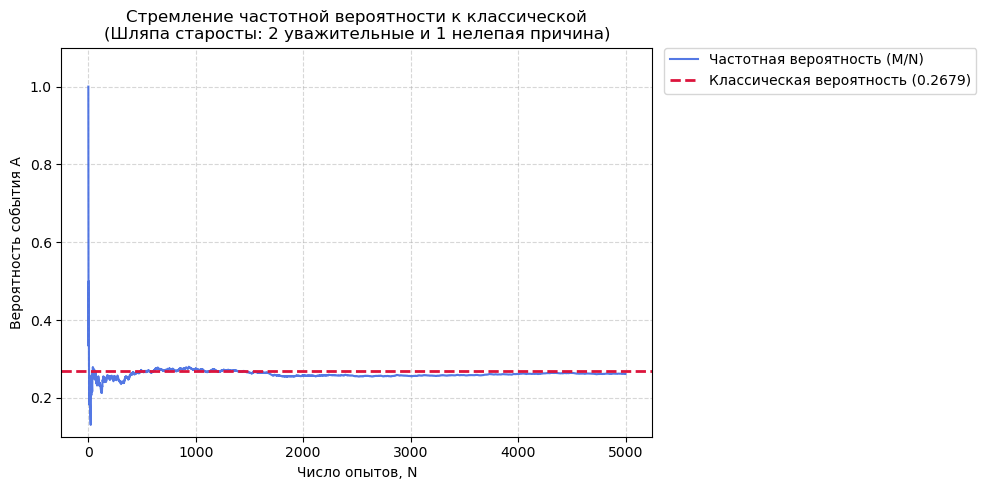

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sc

# Параметры задачи
N_trials = 5000  # количество опытов (вытягиваний 3 бумажек)

np.random.seed(42)

# Моделирование схемы урны через гипергеометрическое распределение.
# ngood = 3 (уважительные), nbad = 5 (нелепые), nsample = 3 (вытягиваем)
# Результат массива - количество вытянутых уважительных причин в каждом опыте
results = np.random.hypergeometric(ngood=3, nbad=5, nsample=3, size=N_trials)

# Событие A: вытянуто ровно 2 уважительные причины
event_occurrences = (results == 2)

# Накопленная сумма наступлений события A к каждому шагу
cumulative_M = np.cumsum(event_occurrences)

# Вектор числа проведенных опытов [1, 2, ..., N]
trials = np.arange(1, N_trials + 1)

# Вычисление частотной вероятности (M/N) для каждого шага
P_freq = cumulative_M / trials

# Теоретическая вероятность
P_theory = (sc.comb(3, 2) * sc.comb(5, 1)) / sc.comb(8, 3)

print(f"Классическая вероятность: {P_theory:.4f}")
print(f"Частотная вероятность (N={N_trials}): {P_freq[-1]:.4f}")

# Визуализация графика
fig, ax = plt.subplots(figsize=(10, 5))

# Отрисовка динамики изменения частотной вероятности
ax.plot(trials, P_freq, color='royalblue', lw=1.5, alpha=0.9, label='Частотная вероятность (M/N)')

# Отрисовка линии классической вероятности
ax.axhline(P_theory, color='crimson', linestyle='--', lw=2, label=f'Классическая вероятность ({P_theory:.4f})')

plt.title('Стремление частотной вероятности к классической\n(Шляпа старосты: 2 уважительные и 1 нелепая причина)')
plt.xlabel('Число опытов, N')
plt.ylabel('Вероятность события A')
plt.ylim(0.1, 1.1)

# Вынос легенды за пределы графика
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()